# Plot the output of the code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.ticker
#from plot_utils import nice_fonts       # Import the nice_fonts settings

In [2]:
# Useful constants
eV = 1.60218e-12  
h = 6.6260755e-27
mJy = 1e-26

### First read and plot the electron density energy distribution per segment

In [3]:
# Read the output of the jet model
NE_output_ord = np.loadtxt('./../Code/Ne_cuts_ord.dat')

# Define quantities for N cuts
Eecut = NE_output_ord[:,0]
necut = NE_output_ord[:,1]

# Take dimensions from array
Ns = int( np.max(NE_output_ord[:,2]) )    # number of segments
m_E = int( len(NE_output_ord[:,2]) / Ns ) # number of energy bins

# Reshape arrays
Eecut = np.reshape(Eecut,(Ns,m_E))
necut = np.reshape(necut,(Ns,m_E))

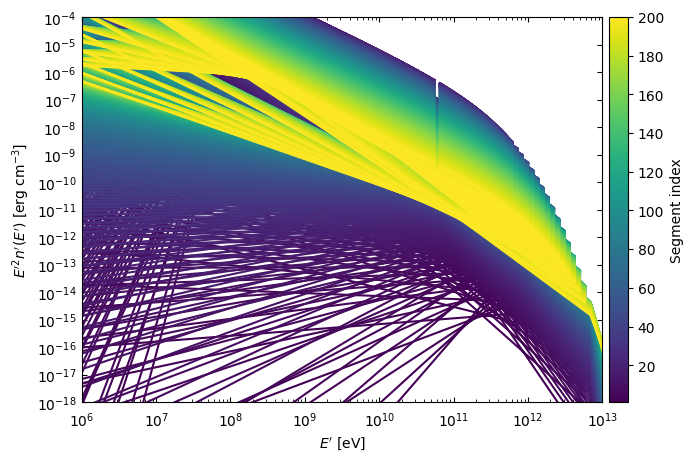

In [4]:
# === Plot ===
fig, ax= plt.subplots(figsize=(8,5))

cmap = matplotlib.colormaps['viridis']
norm = matplotlib.colors.Normalize(vmin=1, vmax=Ns)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

for i in range(Ns):
    ax.loglog(Eecut[i]/eV,necut[i]*Eecut[i]**2, color=cmap(norm(i+1)))

# === Colourbar ===
z_ticks = np.linspace(0, Ns, 11)
cbar = fig.colorbar(sm, ticks=z_ticks, ax=ax, pad=0.01)
cbar.set_label(r"Segment index")

# === Axes limits ===
ymin, ymax = 1e-18, 1e-4
ax.set_xlim([1e6, 1e13])
ax.set_ylim(ymin, ymax)
ax.set_xlabel(r"$E'$ [eV]")
ax.set_ylabel(r"$E'^2 n'(E')$ [erg cm$^{-3}$]")

# === Log ticks ===
x_major = matplotlib.ticker.LogLocator(base=10.0)
x_minor = matplotlib.ticker.LogLocator(base=10.0, subs=np.arange(2, 10)*0.1)
ax.xaxis.set_major_locator(x_major)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.tick_params(axis='x', pad=6)

numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy)
ax.yaxis.set_major_locator(y_major)
y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy*2)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

ax.tick_params(direction='in', which='both', right=True, top=True)

# === Save and show ===
fig.savefig('NEe_cuts.pdf', bbox_inches='tight', pad_inches=0)
plt.show()
plt.close(fig)  # Close the figure to avoid large empty output

### Repeat for the distribution of total number of electrons up to certain heights

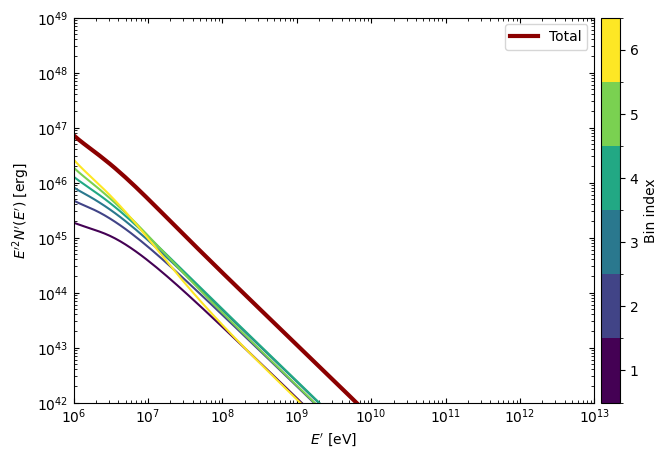

In [5]:
# === Input file ===
fname = '../Code/Ne_bins_total.dat'
data = np.loadtxt(fname, skiprows=1)

E = data[:, 0]
N_bins = data[:, 1:-1]
N_total = data[:, -1]

# === Plot setup ===
fig, ax = plt.subplots(figsize=(8,5))

# Discrete colormap for N_bins_count bins
N_bins_count = N_bins.shape[1]
cmap = matplotlib.colormaps['viridis'].resampled(N_bins_count)
colors = cmap(np.arange(N_bins_count) / (N_bins_count-1))

# Plot each bin
for i in range(N_bins_count):
    ax.loglog(E, N_bins[:, i] * (E*eV)**2, color=colors[i], lw=1.5)

# Plot total in standout colour
ax.loglog(E, (E*eV)**2 * N_total, color='darkred', lw=3, label='Total')

# === Discrete colorbar ===
bounds = np.arange(1, N_bins_count+2) - 0.5  # boundaries for discrete bins
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)
sm = matplotlib.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # required for colorbar
cbar = fig.colorbar(sm, ticks=np.arange(1, N_bins_count+1), pad=0.01, ax=ax)
cbar.set_label('Bin index')

# === Axis limits and labels ===
ax.set_xlim(1e6, 1e13)
ax.set_ylim(1e42, 1e49)
ax.set_xlabel(r"$E'$ [eV]")
ax.set_ylabel(r"$E'^2 N'(E')$ [erg]")
ax.legend(loc='best')

ax.tick_params(direction='in', which='both', right=True, top=True)

fig.savefig('NEe_bins_total.pdf', bbox_inches='tight', pad_inches=0)
plt.show()
plt.close(fig)  # Close the figure to avoid large empty output

### Read the output SEDs per segment

In [6]:
def read_SEDsyn_cuts(filename='../Code/SEDe_syn_cuts_ord.dat'):
    fname = filename
    #fname format: Esy, Esy*Lsy, l
    data = np.loadtxt(fname, skiprows=1).T
    
    E_all, L_all, seg_all = data
    
    # Segment indices (integer)
    seg_all = seg_all.astype(int)
    segments = np.unique(seg_all)
    Ns = len(segments)
    
    # Assume each segment has the same number of points
    NSED_sy = int(np.sum(seg_all == segments[0]))

    print(f'{Ns=}, {NSED_sy=}')

    # Energy grid (assumed identical for all segments)
    Esy = E_all[:NSED_sy]
    
    # Allocate array: Lsy[segment_index, energy_index]
    Lsy = np.zeros((Ns, NSED_sy))

    for i, seg in enumerate(segments):
        mask = seg_all == seg
        Lsy[i] = L_all[mask] / E_all[mask]  # convert from E*L to L

    return Esy, Lsy, Ns, NSED_sy
    
# Read the synchrotron SED at each cut (segment) along the jet; file already sorted in Esy
# Ns and NSED are the number of segments and of energy points, respectively
Esy, Lsy, Ns, NSED = read_SEDsyn_cuts()

Ns=199, NSED_sy=150


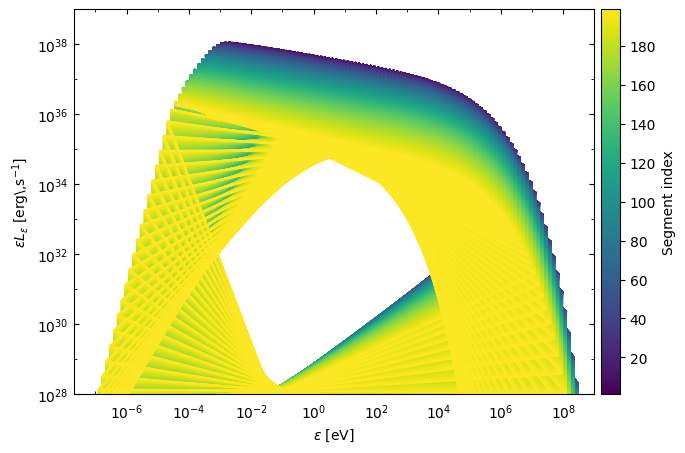

In [7]:
# === Parameters ===
xmin, xmax = 2e-8, 1e9
ymin, ymax = 1e28, 1e39
cmap_name = 'viridis'
output_file = 'SEDsyn_cuts.pdf'

# === Create plot ===
fig, ax = plt.subplots(figsize=(8,5))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_xlabel(r'$\epsilon$ [eV]')
ax.set_ylabel(r'$\epsilon L_{\epsilon}$ [erg\,s$^{-1}$]')

# === Colormap ===
cmap = matplotlib.colormaps[cmap_name]
norm = matplotlib.colors.Normalize(vmin=1, vmax=Ns)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === Plot ===
for i in range(Ns):
    ax.loglog(Esy, Esy * Lsy[i], color=cmap(norm(i+1)))

# === Colourbar ===
z_ticks = np.linspace(0, Ns+1, 11)
#z_ticks = [10, , 1500, 2000, 2500, 3000]
cbar = fig.colorbar(sm, ticks=z_ticks, ax=ax, pad=0.01)
cbar.set_label(r"Segment index")

# === Ticks ===
numx = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base=100.0, numticks=numx)
x_minor = matplotlib.ticker.LogLocator(base=10.0, numticks=numx*2)
ax.xaxis.set_major_locator(x_major)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.tick_params(axis='x', pad=6)

numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base=100.0, numticks=numy)
y_minor = matplotlib.ticker.LogLocator(base=10.0, numticks=numy*2)
ax.yaxis.set_major_locator(y_major)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

ax.tick_params(direction='in', which='both', right=True, top=True)

# === Save and show ===
fig.savefig(output_file, bbox_inches='tight', pad_inches=0)
plt.show()
plt.close(fig)  # Close the figure to avoid large empty output

### Read another output file containing fluxes integrated up to certain heights and total flux

In [20]:
# Define some constants to convert fluxes to luminosities if needed
pc = 3.086e18
D = 16.8e6 * pc
a = 4 * np.pi * D**2

# Read zmin and zmax from the trajectory
traj = np.loadtxt('../Code/trajectory.dat')
zmin = np.min(traj[:,0])
zmax = np.max(traj[:,0])

# === Input file ===
# Read a file containing nu/Hz, F1, F2, ..., Ftot (F1, ... are fluxes integrated up to certain heights) in erg/s/cm2/Hz
fname = '../Code/Flux_e.dat'
data = np.loadtxt(fname, skiprows=2)

# === Extract columns ===
nu = data[:, 0]                   # Hz
E = nu * h                        # Energy
Flux_bins = data[:, 1:-1] / mJy   # 6 flux columns
Flux_total = data[:, -1]  / mJy   # total flux

# Repeat for the CJ
fname = '../Code/FluxCJ_e.dat'
dataCJ = np.loadtxt(fname, skiprows=2)
nuCJ = dataCJ[:, 0]                   # Hz
ECJ = nuCJ * h                        # Energy
FluxCJ_total = dataCJ[:, -1]  / mJy   # total flux

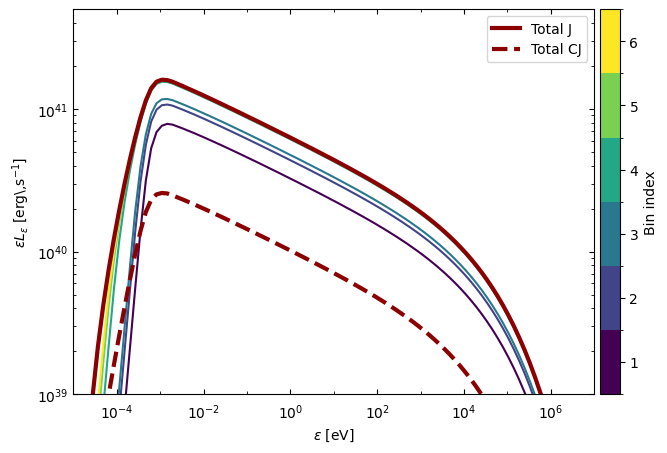

In [21]:
# === Plot setup ===
fig, ax = plt.subplots(figsize=(8,5))

# Discrete colormap for 6 bins
N_bins_count = Flux_bins.shape[1]
cmap = matplotlib.colormaps['viridis'].resampled(N_bins_count)
colors = cmap(np.arange(N_bins_count)/(N_bins_count-1))

# Plot each flux bin
for i in range(N_bins_count):
    ax.loglog(E/eV, Flux_bins[:, i] * mJy * nu * a, color=colors[i], lw=1.5)

# Plot total flux in standout colour
ax.loglog(E/eV, Flux_total * mJy * nu * a, color='darkred', lw=3, label='Total J')
ax.loglog(E/eV, FluxCJ_total * mJy * nuCJ * a, color='darkred', lw=3, linestyle='--', label='Total CJ')

# === Discrete colorbar ===
bounds = np.arange(1, N_bins_count+2) - 0.5
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)
sm = matplotlib.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ticks=np.arange(1, N_bins_count+1), pad=0.01, ax=ax)
cbar.set_label('Bin index')

# === Axis limits and labels ===
ax.set_xlabel(r"$\epsilon$ [eV]")
ax.set_ylabel(r'$\epsilon L_{\epsilon}$ [erg\,s$^{-1}$]')
ax.set_xlim(1e-5, 1e7)
ax.set_ylim(1e39, 5e41)

# === Ticks ===
numx = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base=100.0, numticks=numx)
x_minor = matplotlib.ticker.LogLocator(base=10.0, numticks=numx*2)
ax.xaxis.set_major_locator(x_major)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.tick_params(axis='x', pad=6)
ax.tick_params(direction='in', which='both', right=True, top=True)

ax.legend(loc='best')

# === Save and show ===
fig.savefig('Lum_e_bins.pdf', bbox_inches='tight', pad_inches=0)
plt.show()
plt.close(fig)  # Close the figure to avoid large empty output

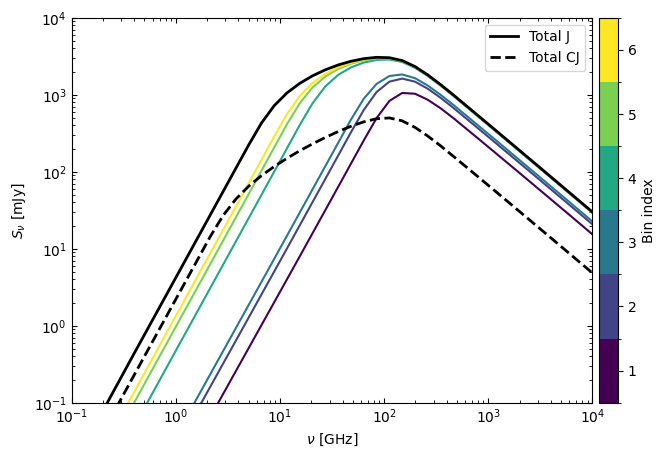

In [24]:
# === Plot setup ===
fig, ax = plt.subplots(figsize=(8,5))

# Discrete colormap for 6 bins
N_bins_count = Flux_bins.shape[1]
cmap = matplotlib.colormaps['viridis'].resampled(N_bins_count)
colors = cmap(np.arange(N_bins_count)/(N_bins_count-1))

# Plot each flux bin
for i in range(N_bins_count):
    ax.loglog(nu/1e9, Flux_bins[:, i], color=colors[i], lw=1.5)

# Plot total flux in standout colour
ax.loglog(nu/1e9, Flux_total, color='black', lw=2, label='Total J')
ax.loglog(nuCJ/1e9, FluxCJ_total, color='black', lw=2, linestyle='--', label='Total CJ')

# === Discrete colorbar ===
bounds = np.arange(1, N_bins_count+2) - 0.5
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)
sm = matplotlib.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ticks=np.arange(1, N_bins_count+1), pad=0.01, ax=ax)
cbar.set_label('Bin index')

# === Axis limits and labels ===
ax.set_xlabel(r"$\nu$ [GHz]")
ax.set_ylabel(r"$S_\nu$ [mJy]")
ax.set_xlim(1e-1, 1e4)
ax.set_ylim(1e-1, 1e4)

ax.tick_params(direction='in', which='both', right=True, top=True)

ax.legend(loc='best')

# === Save and show ===
fig.savefig('Flux_e_bins_radio.pdf', bbox_inches='tight', pad_inches=0)
plt.show()
plt.close(fig)  # Close the figure to avoid large empty output

In [17]:
Flux_bins.shape

(149, 6)